In [1]:
import pandas as pd, numpy as np


ratings = pd.read_csv('data/u.data', sep='\t',
                      names=['user','movie','rating','ts'])

# ---------- پارامترهای کوچک
N_Users  = 200      # حداکثر تعداد کاربر
N_Movies = 300      # حداکثر تعداد فیلم
Max_Ratings = 20    # حداکثر سطر برای هر کاربر 

# ---------- ۱. انتخاب کاربران پر­تعامل 
top_users = (ratings.groupby('user')
                       .size()
                       .sort_values(ascending=False)
                       .head(N_Users)
                       .index)

# ---------- ۲. فیلتر کردن به کاربران منتخب 
sub = ratings[ratings['user'].isin(top_users)].copy()

# ---------- ۳. انتخاب فیلم‌های پرتَکرار در زیرمجموعه 
top_movies = (sub.groupby('movie')
                   .size()
                   .sort_values(ascending=False)
                   .head(N_Movies)
                   .index)
sub = sub[sub['movie'].isin(top_movies)]

# ---------- ۴. محدودکردن تعداد رکورد هر کاربر
sub = (sub.groupby('user')
           .apply(lambda df: df.sample(min(Max_Ratings, len(df)),
                                       random_state=0))
           .reset_index(drop=True))

# نتیجه: دیتاست کوچک‌شده
print(sub.shape)       
sub.to_csv('data/mini_ratings.csv', index=False, sep='\t', header=False)


(4000, 4)


C:\Users\DELL\AppData\Local\Temp\ipykernel_5396\3330836271.py:32: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda df: df.sample(min(Max_Ratings, len(df)),


C:\Users\DELL\AppData\Local\Temp\ipykernel_5396\1841024640.py:36: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  user_docs = ratings.groupby('user').apply(


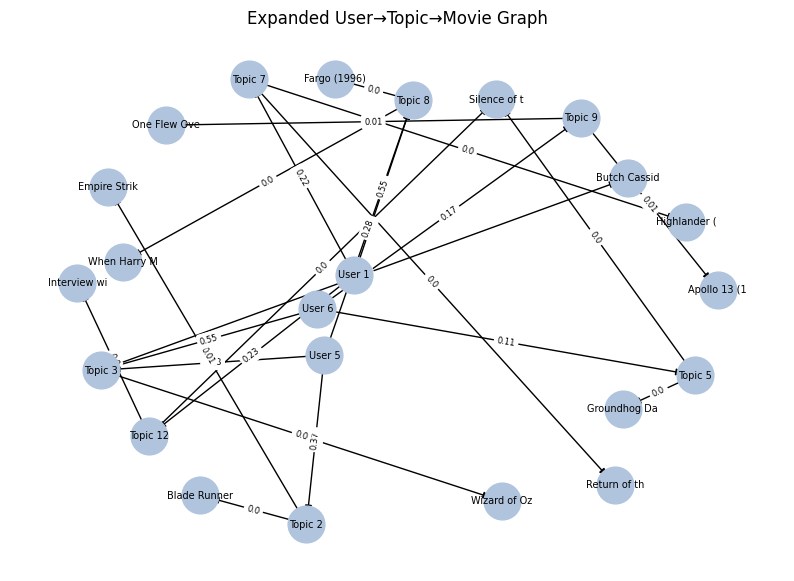


Sample neighbor-based recommendations (with genres):

# User 1
   ! Neighbor 267 (sim=0.86) → Boot, Das (1981) [Action,Drama,War], Ed Wood (1994) [Comedy,Drama], True Romance (1993) [Action,Crime,Romance]
   ! Neighbor 7 (sim=0.86) → Killing Fields, The (1984) [Drama,War], Fugitive, The (1993) [Action,Thriller], True Romance (1993) [Action,Crime,Romance]
   ! Neighbor 64 (sim=0.86) → Shawshank Redemption, The (1994) [Drama], Full Metal Jacket (1987) [Action,Drama,War], Bob Roberts (1992) [Comedy]
   => Recommendations:
      - True Romance (1993)  [Action,Crime,Romance]
      - Forrest Gump (1994)  [Comedy,Romance,War]
      - Boot, Das (1981)  [Action,Drama,War]
      - Ed Wood (1994)  [Comedy,Drama]
      - Die Hard (1988)  [Action,Thriller]
# User 5
   ! Neighbor 606 (sim=0.89) → Blade Runner (1982) [FilmNoir,SciFi], Monty Python and the Holy Grail (1974) [Comedy], Speed (1994) [Action,Romance,Thriller]
   ! Neighbor 886 (sim=0.88) → Rumble in the Bronx (1995) [Action,Adventure,Cri

In [3]:
import os
import re
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import networkx as nx
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation as LDA
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split
from tqdm import tqdm

def load_data():
    Ratings_Path, Raw_u_item = "data/mini_ratings.csv", "data/u.item"
    ratings = pd.read_csv(Ratings_Path, sep='\t', names=['user','movie','rating','ts'])

    if not os.path.exists(Raw_u_item):
        raise FileNotFoundError("u.item not found.")

    genre_names = ['unknown','Action','Adventure','Animation','Childrens','Comedy','Crime','Documentary','Drama',
                   'Fantasy','FilmNoir','Horror','Musical','Mystery','Romance','SciFi','Thriller','War','Western']
    items = pd.read_csv(Raw_u_item, sep='|', encoding='latin-1', names=['movie','title','release','video','imdb']+[f'g{i}' for i in range(19)])
    
    title_map = dict(zip(items['movie'], items['title']))
    genre_map = {row['movie']: [genre_names[i] for i,g in enumerate(row[5:24]) if g==1] or ['unknown'] for _,row in items.iterrows()}
    
    def _clean(t:str)->str: return ' '.join(re.sub(r'[^\w]+',' ',t.lower()).split())
    
    items['content'] = items.apply(lambda r:' '.join([g for g,i in zip(genre_names,r[5:24]) if i==1]+_clean(r['title']).split()),axis=1)
    movie_content = dict(zip(items['movie'], items['content']))
    
    return ratings, items, title_map, genre_map, movie_content

def build_user_docs(ratings, movie_content):
    user_docs = ratings.groupby('user').apply(
        lambda df:' '.join(sum(
            ([f"m{m}"]*int(r)+movie_content[m].split()*int(r) for m,r in df[['movie','rating']].to_numpy()),[]
        ))
    ).rename('doc').reset_index()
    return user_docs

def lda_topic_modeling(user_docs, ratings, movie_content):
    T = 15
    cv = CountVectorizer(token_pattern=r"(?u)\b\w+\b")
    X = cv.fit_transform(user_docs['doc'])
    lda = LDA(n_components=T, random_state=0, learning_method='batch')
    Theta_u = lda.fit_transform(X)
    phi = lda.components_/lda.components_.sum(axis=1, keepdims=True)
    
    movies = ratings['movie'].unique()
    word_index = cv.vocabulary_
    Topic_movie = phi[:, [word_index[f"m{m}"] for m in movies]]
    
    users = ratings['user'].unique()
    u2i = {u:i for i,u in enumerate(users)}
    seen_per_user = ratings.groupby('user')['movie'].apply(set).to_dict()
    
    return Theta_u, phi, Topic_movie, movies, users, u2i, seen_per_user, cv

def draw_graph(Theta_u, Topic_movie, users, movies, u2i, title_map):
    Num_Users, Topics_per_User, Movies_per_Topic = 3, 3, 2
    G = nx.DiGraph()
    for uid in users[:Num_Users]:
        uidx=u2i[uid]; user_theta=Theta_u[uidx]
        G.add_node(f"u{uid}", label=f"User {uid}")
        for t in user_theta.argsort()[-Topics_per_User:][::-1]:
            G.add_node(f"t{t}", label=f"Topic {t}")
            G.add_edge(f"u{uid}", f"t{t}", weight=round(user_theta[t],2))
            for mi in np.argsort(Topic_movie[t])[-Movies_per_Topic:][::-1]:
                mid=movies[mi]
                G.add_node(f"m{mid}", label=title_map[mid][:12])
                G.add_edge(f"t{t}", f"m{mid}", weight=round(Topic_movie[t,mi],2))

    pos=nx.spring_layout(G,seed=2,k=0.6)
    plt.figure(figsize=(10,7))
    node_lbl={n:d['label'] for n,d in G.nodes(data=True)}
    edge_lbl={(u,v):d['weight'] for u,v,d in G.edges(data=True)}
    nx.draw_networkx_nodes(G,pos,node_color='lightsteelblue',node_size=700)
    nx.draw_networkx_labels(G,pos,labels=node_lbl,font_size=7)
    nx.draw_networkx_edges(G,pos,arrows=True,arrowstyle='-|>',arrowsize=10)
    nx.draw_networkx_edge_labels(G,pos,edge_labels=edge_lbl,font_size=6)
    plt.title("Expanded User→Topic→Movie Graph")
    plt.axis('off'); plt.show()

def recommend_and_show(ratings, Theta_u, users, u2i, seen_per_user, title_map, genre_map):
    row_norm = np.linalg.norm(Theta_u, axis=1, keepdims=True); row_norm[row_norm==0]=1
    theta_norm=Theta_u/row_norm
    sim_users=cosine_similarity(theta_norm)

    def topk_neighbors(uid,k=5):
        sims=sim_users[u2i[uid]]; idx=sims.argsort()[-(k+1):-1][::-1]
        return [(users[i], sims[i]) for i in idx]

    def neighbor_recs(uid,k_nei=5,k_rec=5,thr=4):
        nei=topk_neighbors(uid,k_nei); like={}
        for v,s in nei:
            for m in ratings[(ratings['user']==v)&(ratings['rating']>=thr)]['movie']:
                if m in seen_per_user[uid]: continue
                like[m]=like.get(m,0)+s
        top=sorted(like,key=like.get,reverse=True)[:k_rec]
        return top,nei

    def genres_of(m): return ','.join(genre_map[m])

    print("\nSample neighbor-based recommendations (with genres):\n")
    for uid in users[:3]:
        recs, nei = neighbor_recs(uid,3,5)
        print(f"# User {uid}")
        for v,s in nei:
            liked = ', '.join(f"{title_map[m]} [{genres_of(m)}]" for m in ratings[(ratings['user']==v)&(ratings['rating']>=4)]['movie'].head(3))
            print(f"   ! Neighbor {v} (sim={s:.2f}) → {liked}")
        print("   => Recommendations:")
        for m in recs:
            print(f"      - {title_map[m]}  [{genres_of(m)}]")

    return neighbor_recs

def evaluate_hit_rate(ratings, neighbor_recs, users, u2i, movies):
    print("\nEvaluating Hit-Rate@10 …")
    rows = ratings['user'].map(u2i).to_numpy()
    cols = ratings['movie'].map({m:i for i,m in enumerate(movies)}).to_numpy()
    ones = np.ones_like(rows)
    tr, te = train_test_split(np.arange(len(rows)), test_size=0.2, stratify=rows, random_state=42)
    R_test = sp.csr_matrix((ones[te],(rows[te],cols[te])),shape=(len(users),len(movies)))

    hits = total = 0
    for uid in users:
        gt = R_test[u2i[uid]].indices
        if gt.size==0: continue
        recs,_ = neighbor_recs(uid,5,10)
        hits += np.isin(gt,recs).any(); total+=1
    print(f"Hit-Rate@10 = {hits/total:.3f}  (users={total})")
    print("Done ^-^")

def main():
    ratings, items, title_map, genre_map, movie_content = load_data()
    user_docs = build_user_docs(ratings, movie_content)
    Theta_u, phi, Topic_movie, movies, users, u2i, seen_per_user, cv = lda_topic_modeling(user_docs, ratings, movie_content)
    draw_graph(Theta_u, Topic_movie, users, movies, u2i, title_map)
    neighbor_recs = recommend_and_show(ratings, Theta_u, users, u2i, seen_per_user, title_map, genre_map)
    evaluate_hit_rate(ratings, neighbor_recs, users, u2i, movies)

if __name__ == '__main__':
    main()